In [1]:
def add_geometries(rainfall_events_all_df):
    # Get shape file
    regions_shp = "/scratch/hydro5/users/la17355/FUTURE-FLOOD/Results/Pluvial/v4/#ss/plots/most_exposed_events_visualisation/by_region/ukcp18-uk-land-region-hires.shp"
    regions_df = gpd.read_file(regions_shp)

    # Create columns on regions_df and catchments_df (CATCHMENTS) with each of their geometries
    regions_df["region_geometry"] = regions_df.geometry
    CATCHMENTS["catchment_geometry"] = CATCHMENTS.geometry

    # Convert events dataframe to geodataframe
    rainfall_events_all_df = gpd.GeoDataFrame(rainfall_events_all_df,
                            geometry=gpd.points_from_xy(rainfall_events_all_df["x_coord"], rainfall_events_all_df["y_coord"]), 
                                              crs=regions_df.crs)

    # Remove old sjoin columns if this dataframe has been joined before
    rainfall_events_all_df = rainfall_events_all_df.drop(
        columns=["index_right", "geo_region", "region_geometry", "HA_NAME", "catchment_geometry"], errors="ignore")

    # Join events dataframe with the regions geodata
    rainfall_events_all_df = gpd.sjoin(rainfall_events_all_df, regions_df[["geo_region", "region_geometry", "geometry"]],
        how="left", predicate="within")

    # Drop index_right before the next sjoin, or geopandas will error on the clash
    rainfall_events_all_df = rainfall_events_all_df.drop(columns=["index_right"], errors="ignore")

    # Join events dataframe with the catchments geodata
    rainfall_events_all_df = gpd.sjoin(rainfall_events_all_df, CATCHMENTS[["HA_NAME", "catchment_geometry", "geometry"]],
        how="left", predicate="within")

    rainfall_events_all_df = rainfall_events_all_df.drop(columns=["index_right"], errors="ignore")
    return rainfall_events_all_df

def national_and_regional_plot(df, region_col, region_list, value_col, group_col, group_values):
    colors = plt.cm.viridis(np.linspace(0, 1, len(group_values)))
    color_map = dict(zip(group_values, colors))

    def _plot(ax, sub, title):
        summary = sub.groupby([group_col, "intensity_bin"], observed=True)[value_col].mean().unstack()
        # summary =summary.iloc[:,:6]
        for g in group_values:
            if g in summary.index:
                ax.plot(summary.columns, summary.loc[g], marker="o", linewidth=4,
                         markersize=5, color=color_map[g], label=g)
        ax.set_title(title, fontsize=20)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", alpha=0.25)

    fig = plt.figure(figsize=(14, 14))
    n_regions = len(region_list)
    nrows = int(np.ceil(n_regions / 3)) + 1
    gs = gridspec.GridSpec(nrows, 3, height_ratios=[2] + [1]*(nrows-1), hspace=0.5, wspace=0.3)

    ax_national = fig.add_subplot(gs[0, :])
    _plot(ax_national, df, "National")

    for i, region in enumerate(region_list):
        row, col = divmod(i, 3)
        ax = fig.add_subplot(gs[row + 1, col], sharex=ax_national)
        _plot(ax, df[df[region_col] == region], region)

    handles, labels = ax_national.get_legend_handles_labels()
    fig.legend(handles, labels, title=group_col.title(), loc="upper center",
               bbox_to_anchor=(0.5, 0.95), ncol=len(group_values))
    # return fig


In [2]:
def plot_depth_by_intensity_for_timeslices(df):

    binned = (df.groupby(["geo_region", "period", "intensity_bin"],observed=True)["10cm_area"].agg(["mean", "median", "count"])
              .reset_index())

    ### Set colors
    colors = plt.cm.plasma(np.linspace(0, 1, 3))
    timeperiod_colors = dict(zip(reversed(np.unique(df['period'])), colors))

    # fig, axes = plt.subplots(nrows=int(np.ceil(len(region_order) / 3)),ncols=3,figsize=(15, 4 * int(np.ceil(len(region_order) / 3))))
    fig, axes = plt.subplots(5, 3, figsize=(12, 15), sharex=True, sharey=False)
    axes = axes.flatten()

    for ax, region in zip(axes, region_order):

        df = binned[binned["geo_region"] == region]

        for period, group in df.groupby("period",observed=False):

            ax.plot(group["intensity_bin"].astype(str),group["mean"],marker="o",label=period, color = timeperiod_colors[period])

        # ax.set_xlabel("Maximum precipitation")
        ax.set_ylabel("Mean 10cm area")
        ax.set_title(region)

        ax.legend()
        ax.tick_params(labelrotation=45)

    for j in range(len(region_order), 5 * 3):
        axes[j].axis("off")

    fig.suptitle("Changes to Mean per-event flooded area across intensity bins in the future climate");
    fig.tight_layout();

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.gridspec as gridspec
import geopandas as gpd
import sys

sys.path.insert(1, '../../ProcessEvents')
from config import CATCHMENTS

## ------------------------------------------------------------ ###
### Get rainfall events
    And add extra variables
## ------------------------------------------------------------ ###

In [69]:
fp = f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo_and_temporal.pkl"
rainfall_events_all_df = pd.read_pickle(fp)
rainfall_events_all_df = rainfall_events_all_df[rainfall_events_all_df['max_precip']<130].copy()
rainfall_events_all_df = rainfall_events_all_df[rainfall_events_all_df['start_year']>1991].copy()
rainfall_events_all_df["length"] = (rainfall_events_all_df["stop_idx"] - rainfall_events_all_df["start_idx"]).astype("float32")

rainfall_events_all_df['fu_at_peak_old_mm'] = rainfall_events_all_df['fu_at_peak_old']*1000
rainfall_events_all_df['HC_status'] = pd.cut(rainfall_events_all_df['hc_at_peak'],
    bins=[-float('inf'), 0.15, 1.1, 3, float('inf')],labels=['D', 'C', 'B', 'A'], right=False, include_lowest=True)

## ------------------------------------------------------------ ###
### Get spatial data and add regional geometries to rainfall data
## ------------------------------------------------------------ ###

In [70]:
rainfall_events_all_df  = add_geometries(rainfall_events_all_df)

## ------------------------------------------------------------ ###
### Add column defining which of 3 temporal periods an event is within
## ------------------------------------------------------------ ###

In [71]:
conditions = [rainfall_events_all_df["start_year"].between(1990, 2020),rainfall_events_all_df["start_year"].between(2020, 2050),
    rainfall_events_all_df["start_year"].between(2050, 2080),]
periods = ["1990–2020", "2020–2050", "2050–2080"]

rainfall_events_all_df["period"] = np.select(conditions, periods, default=None)

In [102]:
rainfall_events_all_df = rainfall_events_all_df[rainfall_events_all_df['peak_share']<0.8].copy()
print(len(rainfall_events_all_df))
rainfall_events_all_df = rainfall_events_all_df[rainfall_events_all_df['modality'] =='unimodal']
print(len(rainfall_events_all_df))

78430
62769


## ------------------------------------------------------------ ###
### Add column defining intensity bins
## ------------------------------------------------------------ ###

In [103]:
bins = [30, 35, 40, 45, 50, 60, 70, np.inf]
# bins = [30,  40,  50, 60, 70, np.inf]
intensity_labels = [f"{bins[i]}–{bins[i+1]}" for i in range(len(bins)-2)] + ["100+"]
rainfall_events_all_df["intensity_bin"] = pd.cut(rainfall_events_all_df["max_precip"], bins=bins, labels=intensity_labels,
                                                 include_lowest=True)

In [104]:
bins = [0, 20, 40, 60, 80, 100]
loading_labels = [f"{bins[i]}–{bins[i+1]}" for i in range(len(bins)-1)] 
rainfall_events_all_df["loading_bin"] = pd.cut(rainfall_events_all_df["d50_n"], bins=bins, labels=loading_labels, 
                                               include_lowest=True)


bins = [0, 0.20, 0.40, 0.60, 0.80, 1]
peak_share_labels = [f"{bins[i]}–{bins[i+1]}" for i in range(len(bins)-1)] 
rainfall_events_all_df["peak_share_bin"] = pd.cut(rainfall_events_all_df["peak_share"], bins=bins, labels=loading_labels, 
                                               include_lowest=True)

rainfall_events_all_df["peak_class"] = pd.cut(rainfall_events_all_df["peak_share"], [0, 0.5, 0.8, 1.0], 
                                              labels=["spread", "mixed", "peak-dominated"], include_lowest=True)


### Plots of the mean flooded area for events of different intensities

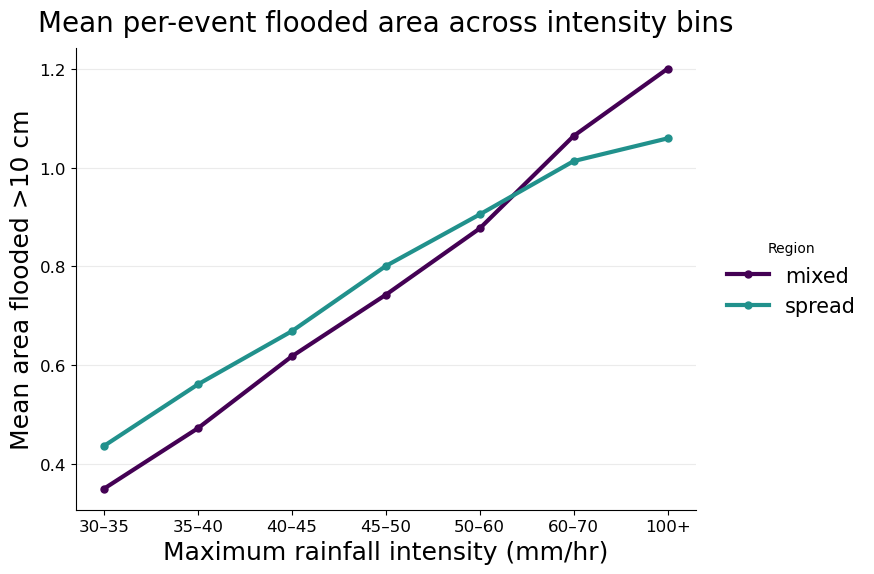

In [105]:
summary = (rainfall_events_all_df.groupby(["peak_class", "intensity_bin"], observed=True)["10cm_area"].mean().unstack())

colors = plt.cm.viridis(np.linspace(0, 1, 3))

fig, ax = plt.subplots(figsize=(8, 6))

# -------------------------
# LEFT: rainfall plot
# -------------------------

for region, color in zip(reversed(["spread", "mixed"]), colors):
    ax.plot(summary.columns,summary.loc[region],marker="o",linewidth=3,markersize=5,color=color,label=region)

ax.set_xlabel("Maximum rainfall intensity (mm/hr)", fontsize=18)
ax.set_ylabel("Mean area flooded >10 cm", fontsize=18)
ax.set_title("Mean per-event flooded area across intensity bins",
             fontsize=20, pad=12)

ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", which="major", labelsize=12)

ax.legend(title="Region",bbox_to_anchor=(1.02, 0.5),loc="center left",frameon=False,fontsize=15)



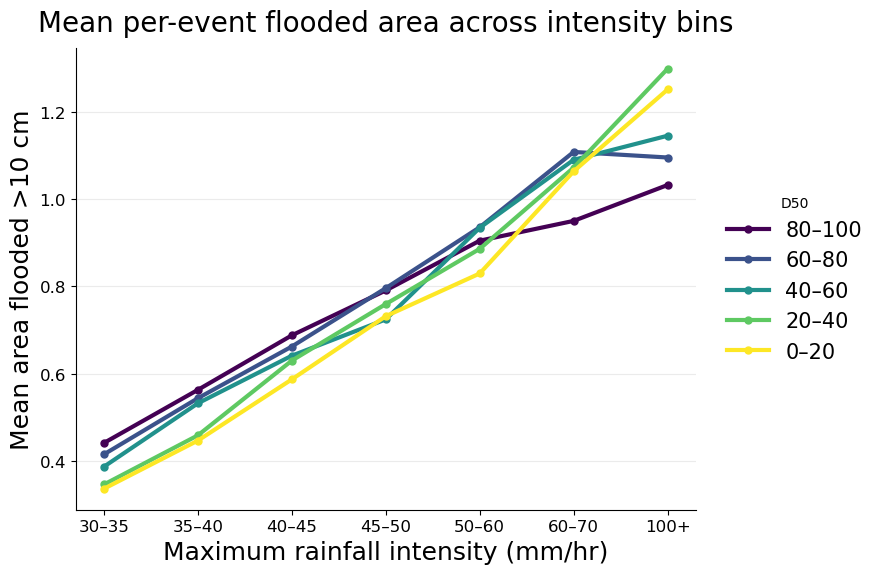

In [107]:
summary = (rainfall_events_all_df.groupby(["loading_bin", "intensity_bin"], observed=True)["10cm_area"].mean().unstack())

colors = plt.cm.viridis(np.linspace(0, 1, 5))

fig, ax = plt.subplots(figsize=(8, 6))
for region, color in zip(reversed(loading_labels), colors):
    ax.plot(summary.columns,summary.loc[region],marker="o",linewidth=3,markersize=5,color=color,label=region)

ax.set_xlabel("Maximum rainfall intensity (mm/hr)", fontsize=18)
ax.set_ylabel("Mean area flooded >10 cm", fontsize=18)
ax.set_title("Mean per-event flooded area across intensity bins",
             fontsize=20, pad=12)

ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", which="major", labelsize=12)

ax.legend(title="D50",bbox_to_anchor=(1.02, 0.5),loc="center left",frameon=False,fontsize=15)



In [112]:
res

,facet,int_bin,d50_bin,n,dev,lo,hi
0,low,30-35,0-20,6355,-0.018498,-0.026049,-0.009709
1,low,30-35,20-40,3282,-0.023165,-0.033924,-0.011551
2,low,30-35,40-60,2144,0.009268,-0.004951,0.025197
3,low,30-35,60-80,2174,0.031166,0.016854,0.046524
4,low,30-35,80-100,1774,0.059726,0.041549,0.075454
...,...,...,...,...,...,...,...
70,high,70+,0-20,411,0.069953,-0.021428,0.177669
71,high,70+,20-40,192,0.117460,-0.031803,0.275622
72,high,70+,40-60,120,-0.035885,-0.167720,0.111058
73,high,70+,60-80,151,-0.085732,-0.223111,0.081116


Events per intensity bin x D50 class:
 d50_bin   0-20  20-40  40-60  60-80  80-100
int_bin                                    
30-35    10301   6363   4816   4712    3538
35-40     5346   3165   2360   2308    1765
40-45     2923   1618   1249   1259     902
45-50     1587    871    680    620     488
50-60     1324    739    512    493     463
60-70      454    263    175    176     196
70+        411    192    120    151     229

Mean total_acc by D50 class (is D50 confounded with total_acc?):
 d50_bin
0-20      64.21
20-40     68.17
40-60     71.43
60-80     70.00
80-100    69.05
Name: total_acc, dtype: float64


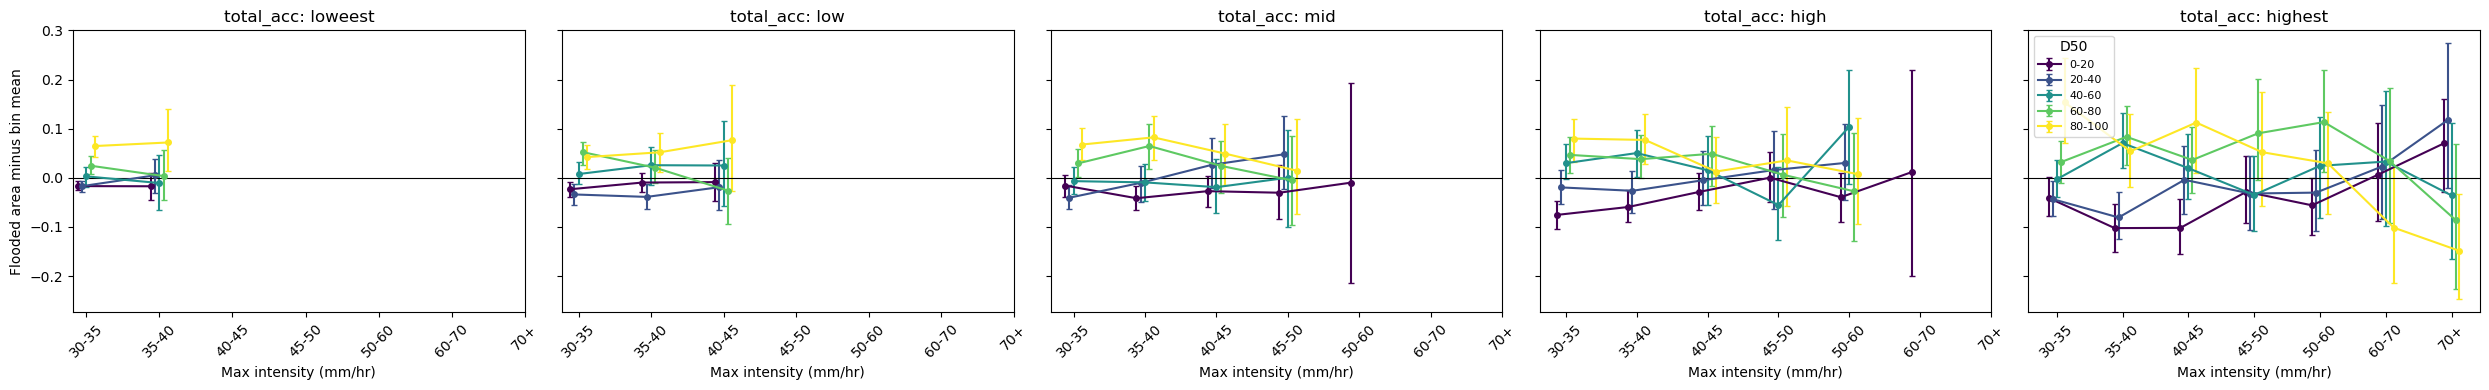

In [113]:
"""
D50 effect within intensity bins, with uncertainty, and repeated within levels of a control variable.
Plots (mean flooded area in a D50 class) minus (mean for ALL events in the same intensity bin), so a line above 0
means that D50 class floods more than average for that intensity.
"""

ev = rainfall_events_all_df

OUT, INT, D50 = "10cm_area", "max_precip", "d50_n"        # d50_n on a 0-100 scale
FACET = "total_acc"                                       # control variable to hold roughly fixed (try hc_class, capacity, length_of_active_rain)
INT_BINS = [30, 35, 40, 45, 50, 60, 70, np.inf]
INT_LAB = ["30-35", "35-40", "40-45", "45-50", "50-60", "60-70", "70+"]
D50_BINS = [0, 20, 40, 60, 80, 100]
D50_LAB = ["0-20", "20-40", "40-60", "60-80", "80-100"]
MIN_N = 30

d = ev.dropna(subset=[OUT, INT, D50, FACET]).copy()
d["int_bin"] = pd.cut(d[INT], INT_BINS, labels=INT_LAB, right=False)
d["d50_bin"] = pd.cut(d[D50], D50_BINS, labels=D50_LAB, include_lowest=True)
d["facet"] = pd.qcut(d[FACET], 5, labels=["loweest", "low", "mid", "high", "highest"]) if d[FACET].nunique() > 6 else d[FACET].astype(str)

print("Events per intensity bin x D50 class:\n", pd.crosstab(d["int_bin"], d["d50_bin"]))
print(f"\nMean {FACET} by D50 class (is D50 confounded with {FACET}?):\n", d.groupby("d50_bin", observed=True)[FACET].mean().round(2))

rng = np.random.default_rng(0)
def ci(x, ref, n=500):
    b = [rng.choice(x, len(x)).mean() - ref for _ in range(n)]
    return np.percentile(b, [2.5, 97.5])

rows = []
for (f, ib), g in d.groupby(["facet", "int_bin"], observed=True):
    ref = g[OUT].mean()                                    # mean over all D50 classes in this cell
    for db, h in g.groupby("d50_bin", observed=True):
        if len(h) >= MIN_N:
            lo, hi = ci(h[OUT].values, ref)
            rows.append({"facet": f, "int_bin": ib, "d50_bin": db, "n": len(h), "dev": h[OUT].mean() - ref, "lo": lo, "hi": hi})
res = pd.DataFrame(rows)

facets = list(res["facet"].unique())
fig, axes = plt.subplots(1, len(facets), figsize=(5 * len(facets), 4), sharey=True)
axes = np.atleast_1d(axes)
cmap = plt.cm.viridis(np.linspace(0, 1, len(D50_LAB)))
for ax, f in zip(axes, facets):
    for c, db in zip(cmap, D50_LAB):
        s = res[(res.facet == f) & (res.d50_bin == db)].set_index("int_bin").reindex(INT_LAB)
        x = np.arange(len(INT_LAB)) + (D50_LAB.index(db) - 2) * 0.06
        ax.errorbar(x, s["dev"], yerr=[s["dev"] - s["lo"], s["hi"] - s["dev"]], fmt="o-", color=c, ms=4, lw=1.5, capsize=2, label=db)
    ax.axhline(0, c="k", lw=0.8); ax.set_xticks(range(len(INT_LAB))); ax.set_xticklabels(INT_LAB, rotation=45)
    ax.set_title(f"{FACET}: {f}"); ax.set_xlabel("Max intensity (mm/hr)")
axes[0].set_ylabel("Flooded area minus bin mean"); axes[-1].legend(title="D50", fontsize=8)
plt.tight_layout(); plt.show()

In [116]:
list(ev.columns)

['max_precip',
 't_global',
 't_local',
 'x_idx',
 'y_idx',
 'x_idx_global',
 'y_idx_global',
 'x_coord',
 'y_coord',
 'ens',
 'start_idx',
 'stop_idx',
 'max_precip_from_csv',
 'start_year',
 'month',
 'event_num',
 'time_mismatch',
 'rainfall_peak_day',
 'hydro_day_360',
 'day_360',
 't_local_rebased',
 'total_acc',
 'peak_position_ratio',
 'd50',
 'gini',
 'time_based_std',
 'dry_ratio',
 'max_quartile_index',
 'times',
 'values',
 'mismatch',
 '10cm_area',
 '10cm_volume',
 '30cm_area',
 '30cm_volume',
 'hc_at_peak',
 'mean_sm_2_before_event',
 'mean_sm_3_before_event',
 'mean_sm_4_before_event',
 'mean_sm_5_before_event',
 'neighbourhood_rain_total',
 'neighbourhood_rain_sum_excl_peak',
 'neighbourhood_n_cells',
 'neighbourhood_flood_10_area',
 'neighbourhood_flood_10_vol',
 'neighbourhood_flood_30_area',
 'neighbourhood_flood_30_vol',
 'threshold_rain_total_t50',
 'threshold_n_cells_t50',
 'cluster_rain_total_t50',
 'cluster_n_cells_t50',
 'threshold_flood_10_area_t50',
 'cluster_

                          group     n  pct_more_flooding   lo   hi
                     ALL events 45860               21.2 18.9 23.5
30-50 mm/hr, high fumax_at_peak 20535               54.6 50.3 58.9
 30-50 mm/hr, low fumax_at_peak 20820               14.1 11.7 16.5
  50+ mm/hr, high fumax_at_peak  2404               13.8  6.9 20.7
   50+ mm/hr, low fumax_at_peak  2101                5.6 -2.1 13.3


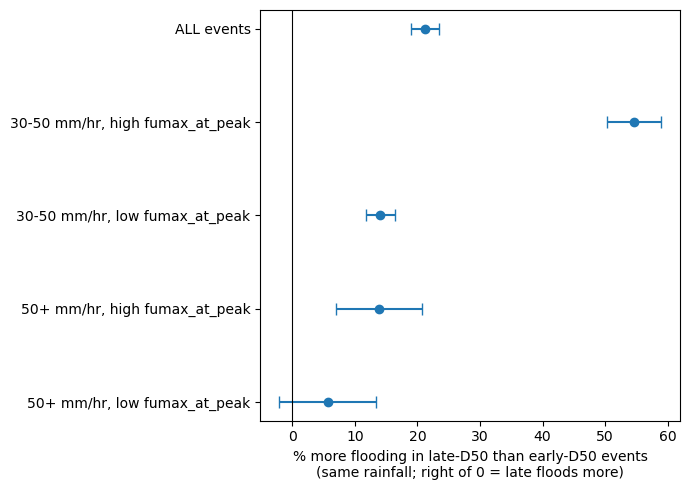

In [121]:
"""
Simple question: do late-D50 events flood more than early-D50 events with the same rainfall?
Reports one number (% difference in flooded area) overall, and for 2 intensity bands x 2 capacity groups.
"""

OUT, D50 = "10cm_area", "d50_n"                       # d50_n on a 0-100 scale
CONTROLS = ["max_precip", "total_acc", "length_of_active_rain"]
STATE = "fumax_at_peak"                                    # one cell-state variable to split on (edit)
INT_SPLIT = 50                                        # mm/hr dividing 'lower' and 'higher' intensity
MIN_N = 300

d = ev.dropna(subset=[OUT, D50, STATE] + CONTROLS).rename(columns={OUT: "y"})
d = d[(d[D50] < 33) | (d[D50] > 67)].copy()           # compare clearly early vs clearly late events, drop the middle
d["late"] = (d[D50] > 67).astype(int)
d["intensity"] = np.where(d["max_precip"] < INT_SPLIT, f"{int(d.max_precip.min())}-{INT_SPLIT} mm/hr", f"{INT_SPLIT}+ mm/hr")
d["state"] = np.where(d[STATE] < d[STATE].median(), f"low {STATE}", f"high {STATE}")

def late_vs_early(g):
    fit = smf.ols("y ~ late + " + " + ".join(CONTROLS), g).fit(cov_type="HC3")   # late vs early, holding the rainfall variables fixed
    base = g.loc[g.late == 0, "y"].mean()                                         # typical flooded area for EARLY events
    lo, hi = fit.conf_int().loc["late"]
    return {"n": len(g), "pct_more_flooding": 100 * fit.params["late"] / base, "lo": 100 * lo / base, "hi": 100 * hi / base}

rows = [{"group": "ALL events", **late_vs_early(d)}]
for (i, s), g in d.groupby(["intensity", "state"]):
    if len(g) >= MIN_N and g.late.nunique() == 2:
        rows.append({"group": f"{i}, {s}", **late_vs_early(g)})
res = pd.DataFrame(rows)
print(res.round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 0.7 * len(res) + 1.5))
y = np.arange(len(res))[::-1]
ax.errorbar(res["pct_more_flooding"], y, xerr=[res["pct_more_flooding"] - res["lo"], res["hi"] - res["pct_more_flooding"]], fmt="o", capsize=4)
ax.axvline(0, c="k", lw=0.8); ax.set_yticks(y); ax.set_yticklabels(res["group"])
ax.set_xlabel("% more flooding in late-D50 than early-D50 events\n(same rainfall; right of 0 = late floods more)")
plt.tight_layout(); plt.show()

  intensity   state     n  pct    lo   hi
 All events     All 45855 15.2  13.0 17.4
30-50 mm/hr High SM 20530 19.4  15.7 23.2
30-50 mm/hr  Low SM 20821 21.8  18.8 24.9
  50+ mm/hr High SM  2398 -4.1 -11.2  2.9
  50+ mm/hr  Low SM  2106  5.3  -3.2 13.7


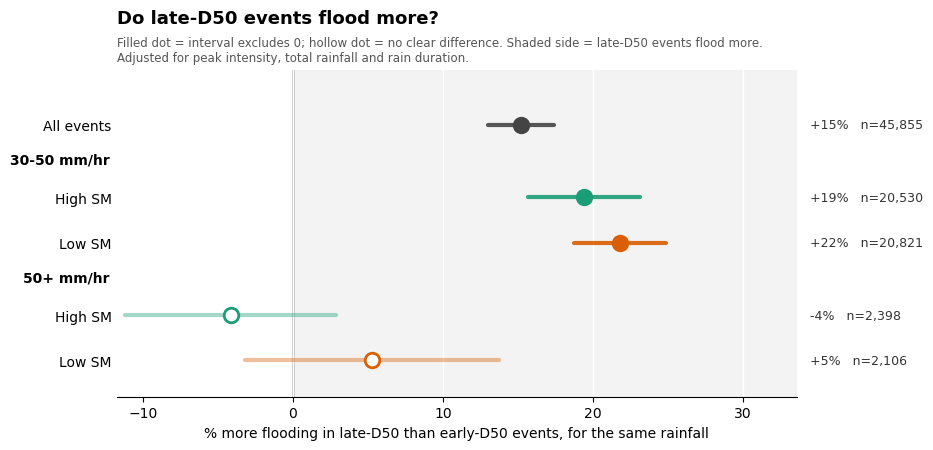

In [132]:
"""
Simple question: do late-D50 events flood more than early-D50 events with the same rainfall?
Adjusts for the rainfall variables in CONTROLS (peak intensity, total accumulation, active rain length).
Reports % difference in flooded area overall, and for 2 intensity bands x 2 state groups, with a clean summary plot.
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

OUT, D50 = "10cm_area", "d50_n"                       # d50_n on a 0-100 scale
CONTROLS = ["max_precip", "total_acc"]
STATE, STATE_LABEL = "mean_sm_2_before_event", "SM"           # one cell-state variable to split on (edit)
INT_SPLIT = 50                                        # mm/hr dividing 'lower' and 'higher' intensity
MIN_N = 300

d = ev.dropna(subset=[OUT, D50, STATE] + CONTROLS).rename(columns={OUT: "y"})
d = d[(d[D50] < 33) | (d[D50] > 67)].copy()           # clearly early vs clearly late events
d["late"] = (d[D50] > 67).astype(int)
lo_lab, hi_lab = f"{int(d.max_precip.min())}-{INT_SPLIT} mm/hr", f"{INT_SPLIT}+ mm/hr"
d["intensity"] = np.where(d["max_precip"] < INT_SPLIT, lo_lab, hi_lab)
d["state"] = np.where(d[STATE] < d[STATE].median(), f"Low {STATE_LABEL}", f"High {STATE_LABEL}")

def late_vs_early(g):
    fit = smf.ols("y ~ late + " + " + ".join(CONTROLS), g).fit(cov_type="HC3")
    base = g.loc[g.late == 0, "y"].mean()
    lo, hi = fit.conf_int().loc["late"]
    return {"n": len(g), "pct": 100 * fit.params["late"] / base, "lo": 100 * lo / base, "hi": 100 * hi / base}

rows = [{"intensity": "All events", "state": "All", **late_vs_early(d)}]
for (i, s), g in d.groupby(["intensity", "state"]):
    if len(g) >= MIN_N and g.late.nunique() == 2:
        rows.append({"intensity": i, "state": s, **late_vs_early(g)})
res = pd.DataFrame(rows)
print(res.round(1).to_string(index=False))

# ----------------------------------------------------------------------------------------------------------
# PLOT
# ----------------------------------------------------------------------------------------------------------
colours = {f"Low {STATE_LABEL}": "#d95f02", f"High {STATE_LABEL}": "#1b9e77", "All": "#444444"}
ypos, y = [], 0
for k, (i, g) in enumerate(res.groupby("intensity", sort=False)):
    if k > 0: y -= 0.6                                    # gap between groups
    for _ in range(len(g)):
        ypos.append(y); y -= 1
res["y"] = ypos

fig, ax = plt.subplots(figsize=(10, 4.8))
xmax = max(abs(res[["lo", "hi"]].values).max(), 5) * 1.35
ax.axvspan(0, xmax, color="#f3f3f3", zorder=0); ax.axvline(0, color="k", lw=1, zorder=1)
for _, r in res.iterrows():
    sig = (r.lo > 0) or (r.hi < 0)
    c = colours[r.state]
    ax.plot([r.lo, r.hi], [r.y, r.y], color=c, lw=3, alpha=0.9 if sig else 0.4, solid_capstyle="round", zorder=2)
    ax.scatter(r.pct, r.y, s=110, color=c if sig else "white", edgecolor=c, linewidth=2, zorder=3)
    ax.text(1.02, r.y, f"{r.pct:+.0f}%   n={int(r.n):,}", transform=ax.get_yaxis_transform(), va="center", ha="left", fontsize=9, color="#333")

labels = [("All events" if r.state == "All" else r.state) for _, r in res.iterrows()]
ax.set_yticks(res["y"]); ax.set_yticklabels(labels, fontsize=10)
for i, g in res.groupby("intensity", sort=False):                  # intensity-band headers
    if i != "All events":
        ax.text(-0.01, g["y"].max() + 0.75, i, transform=ax.get_yaxis_transform(), ha="right", fontsize=10, fontweight="bold")
ax.set_xlim(-xmax * 0.35, xmax); ax.set_ylim(res["y"].min() - 0.8, res["y"].max() + 1.2)
ax.set_xlabel("% more flooding in late-D50 than early-D50 events, for the same rainfall")
ax.set_title("Do late-D50 events flood more?", loc="left", fontsize=13, fontweight="bold", pad=34)
ax.text(0, 1.02, "Filled dot = interval excludes 0; hollow dot = no clear difference. Shaded side = late-D50 events flood more.\n"
        "Adjusted for peak intensity, total rainfall and rain duration.", transform=ax.transAxes, fontsize=8.5, color="#555", va="bottom")
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
ax.tick_params(axis="y", length=0); ax.grid(axis="x", color="white", lw=1, zorder=1)
plt.subplots_adjust(left=0.18, right=0.86, top=0.82, bottom=0.14); plt.savefig("d50_comparison.png", dpi=200); plt.show()

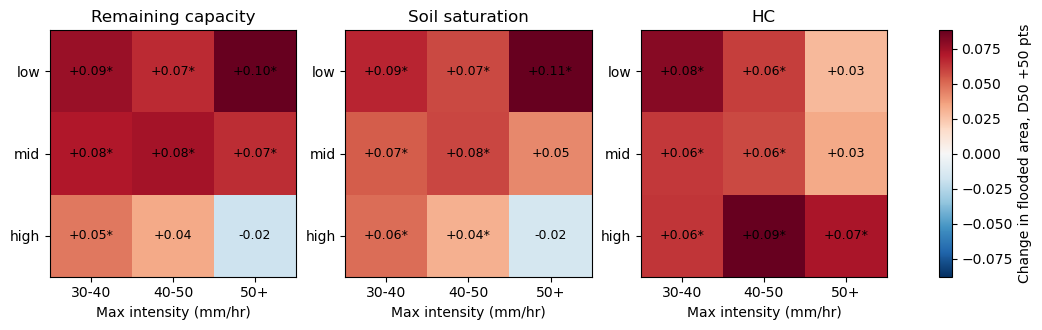

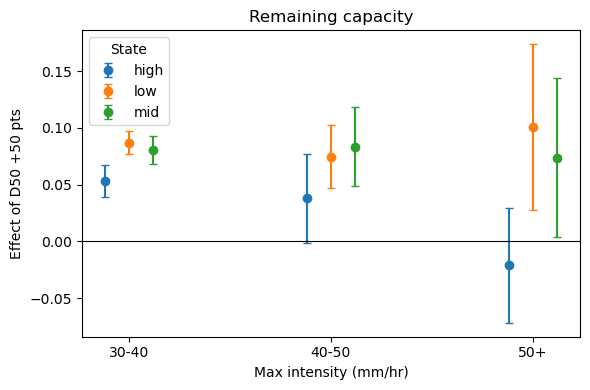

 grp  band     n  effect     lo    hi
high 30-40 14535   0.053  0.039 0.067
high 40-50  3986   0.038 -0.001 0.077
high   50+  2402  -0.021 -0.072 0.030
 low 30-40 15154   0.087  0.077 0.097
 low 40-50  4149   0.075  0.047 0.102
 low   50+  1620   0.101  0.028 0.174
 mid 30-40 14985   0.081  0.069 0.093
 mid 40-50  4062   0.084  0.049 0.118
 mid   50+  1876   0.074  0.004 0.144


In [119]:
"""
How big is the D50 effect, and does it depend on peak intensity and on the state of the cell?
For each (state group x intensity band) it fits   area ~ D50 + rainfall controls   and reports the D50 effect
as 'change in flooded area when D50 goes from early to late' (+SHIFT points), with a 95% interval.
Shown as a heatmap (one number per cell) and a dot-and-whisker plot.
"""

OUT, D50 = "10cm_area", "d50_n"                           # d50_n on a 0-100 scale
CONTROLS = ["max_precip", "total_acc", "length_of_active_rain"]
STATE_COLS = {"Remaining capacity": "sat_at_peak_old",           # edit: label -> column name (event-varying and/or static state variables)
              "Soil saturation": "sat_at_peak_new",
              "HC": "fumax_at_peak"}
INT_EDGES, INT_LAB = [30, 40, 50, np.inf], ["30-40", "40-50", "50+"]
MIN_N = 200
SHIFT = 50                                                # early (D50 ~25) -> late (D50 ~75)

def effect_table(d, state_col):
    d = d.rename(columns={OUT: "y"}).copy()
    if d[state_col].nunique() <= 5 or not np.issubdtype(d[state_col].dtype, np.number):
        d["grp"] = d[state_col].astype(str)                                       # already classes (e.g. HC class)
    else:
        d["grp"] = pd.qcut(d[state_col].rank(method="first"), 3, labels=["low", "mid", "high"]).astype(str)
    d["band"] = pd.cut(d["max_precip"], INT_EDGES, labels=INT_LAB, right=False)
    rows = []
    for (s, b), g in d.groupby(["grp", "band"], observed=True):
        if len(g) < MIN_N:
            continue
        fit = smf.ols(f"y ~ {D50} + {' + '.join(CONTROLS)}", data=g).fit(cov_type="HC3")
        lo, hi = fit.conf_int().loc[D50] * SHIFT
        rows.append({"grp": s, "band": b, "n": len(g), "effect": fit.params[D50] * SHIFT, "lo": lo, "hi": hi})
    return pd.DataFrame(rows)

def plot_heatmap(t, title, ax):
    order = [g for g in ["low", "mid", "high"] if g in set(t.grp)] or sorted(t.grp.unique())
    piv = t.pivot(index="grp", columns="band", values="effect").reindex(index=order, columns=INT_LAB)
    sig = t.assign(s=(t.lo > 0) | (t.hi < 0)).pivot(index="grp", columns="band", values="s").reindex(index=order, columns=INT_LAB)
    lim = np.nanmax(np.abs(piv.values))
    im = ax.imshow(piv.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(len(INT_LAB))); ax.set_xticklabels(INT_LAB); ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            v = piv.values[i, j]
            ax.text(j, i, "n/a" if np.isnan(v) else f"{v:+.2f}" + ("*" if sig.values[i, j] == True else ""),
                    ha="center", va="center", fontsize=9, color="grey" if np.isnan(v) else "black")
    ax.set_title(title); ax.set_xlabel("Max intensity (mm/hr)")
    return im

d = ev.dropna(subset=[OUT, D50] + CONTROLS + list(STATE_COLS.values())).copy()
tables = {lab: effect_table(d, col) for lab, col in STATE_COLS.items()}

# --- Plot 1: heatmaps. Red = late-D50 events flood MORE, blue = LESS; * = interval excludes 0; n/a = too few events ---
fig, axes = plt.subplots(1, len(tables), figsize=(4.5 * len(tables), 3.2), sharex=True)
for ax, (lab, t) in zip(np.atleast_1d(axes), tables.items()):
    im = plot_heatmap(t, lab, ax)
plt.colorbar(im, ax=axes, label=f"Change in flooded area, D50 +{SHIFT} pts"); plt.show()

# --- Plot 2: dot-and-whisker for one state variable ---
lab = list(STATE_COLS)[0]; t = tables[lab]
fig, ax = plt.subplots(figsize=(6, 4))
for k, (g, h) in enumerate(t.groupby("grp")):
    x = np.array([INT_LAB.index(b) for b in h["band"]]) + (k - 1) * 0.12
    ax.errorbar(x, h["effect"], yerr=[h["effect"] - h["lo"], h["hi"] - h["effect"]], fmt="o", capsize=3, label=g)
ax.axhline(0, c="k", lw=0.8); ax.set_xticks(range(len(INT_LAB))); ax.set_xticklabels(INT_LAB)
ax.set_xlabel("Max intensity (mm/hr)"); ax.set_ylabel(f"Effect of D50 +{SHIFT} pts"); ax.set_title(lab); ax.legend(title="State")
plt.tight_layout(); plt.show()
print(tables[lab].round(3).to_string(index=False))

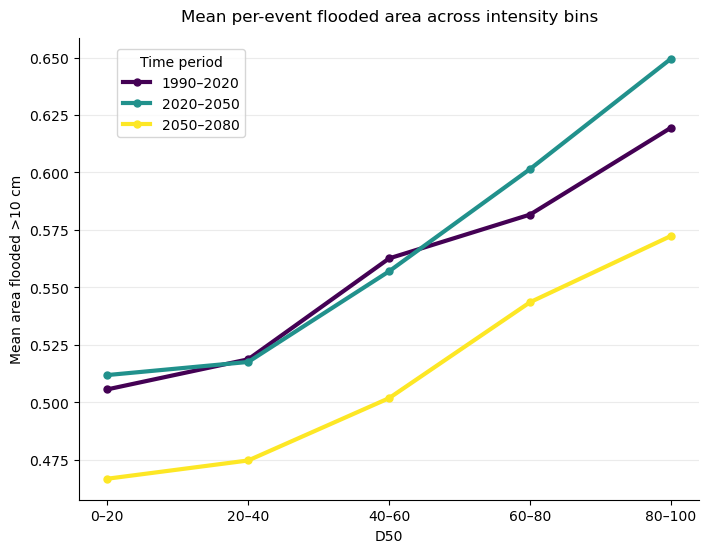

In [97]:
bins = [0, 20, 40, 60, 80, 100]
labels = [f"{bins[i]}–{bins[i+1]}" for i in range(len(bins)-1)] 
rainfall_events_all_df["loading_bin"] = pd.cut(rainfall_events_all_df["d50_n"], bins=bins, labels=labels, include_lowest=True)
summary = (rainfall_events_all_df.groupby(["period", "loading_bin"], observed=True)["10cm_area"].mean().unstack())
# summary =summary.iloc[:,:4]
colors = plt.cm.viridis(np.linspace(0, 1, len(summary.index)))

# Your plot currently reverses the region order, so make the same mapping
region_colors = dict(zip(reversed(labels), colors))

fig, ax = plt.subplots(figsize=(8, 6))

for period, color in zip(summary.index, colors):
    ax.plot(summary.columns,summary.loc[period],marker="o",linewidth=3,markersize=5,color=color,label=period)    
    
ax.set_xlabel("D50")
ax.set_ylabel("Mean area flooded >10 cm")
ax.set_title("Mean per-event flooded area across intensity bins",pad=12)

ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
# ax.tick_params(axis="both", which="major", labelsize=12)

ax.legend(title="Time period",bbox_to_anchor=(0.05, 0.88),loc="center left",frameon=True);

In [10]:
region_order = ["North Scotland","East Scotland","West Scotland","North West England","North East England",
                "Yorkshire and Humber","West Midlands","East Midlands","East of England","Wales",
                "South West England","South East England","London"]

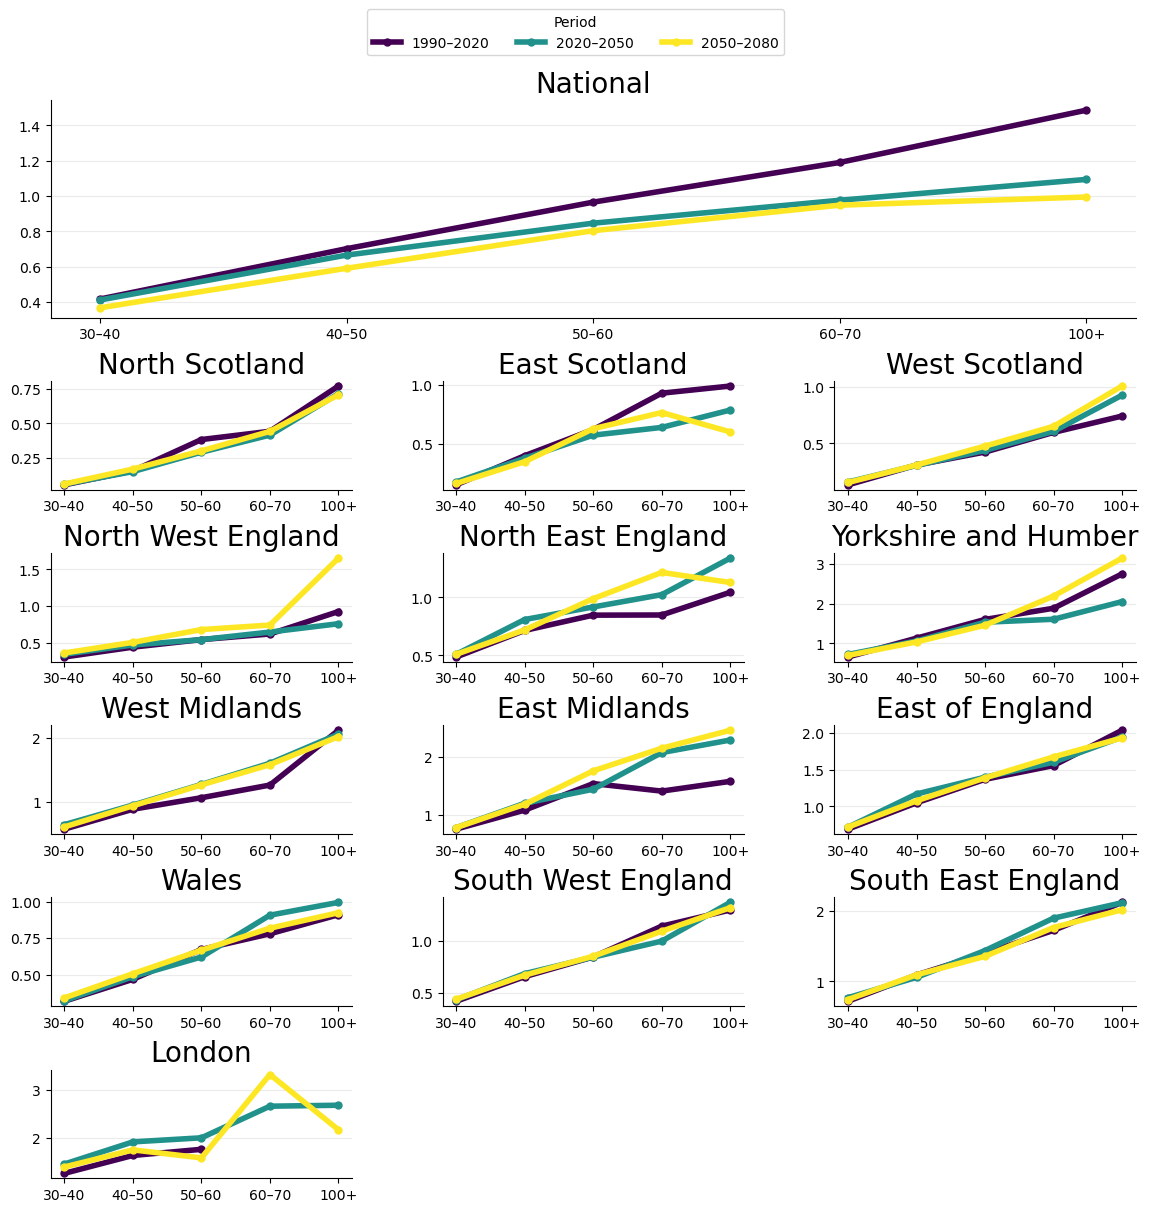

In [11]:
national_and_regional_plot(rainfall_events_all_df, 'geo_region', region_order, '10cm_area', "period", periods)

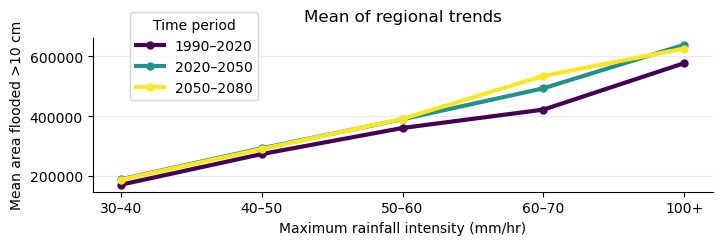

In [12]:
regional_means = (rainfall_events_all_df
    .groupby(["geo_region", "period", "intensity_bin"], observed=True)["10cm_volume"].mean().reset_index())
national_as_mean_of_regions = (
    regional_means.groupby(["period", "intensity_bin"], observed=True)["10cm_volume"].mean().unstack())

fig, ax = plt.subplots(figsize=(8, 2))

for choice, color in zip(periods, colors):
    ax.plot(national_as_mean_of_regions.columns,national_as_mean_of_regions.loc[choice],marker="o",linewidth=3,markersize=5,
            color=color,label=choice)

ax.set_xlabel("Maximum rainfall intensity (mm/hr)")
ax.set_ylabel("Mean area flooded >10 cm")
ax.set_title("Mean of regional trends",pad=12)

ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
# ax.tick_params(axis="both", which="major", labelsize=12)

ax.legend(title="Time period",bbox_to_anchor=(0.05, 0.88),loc="center left",frameon=True);

## Split by event length

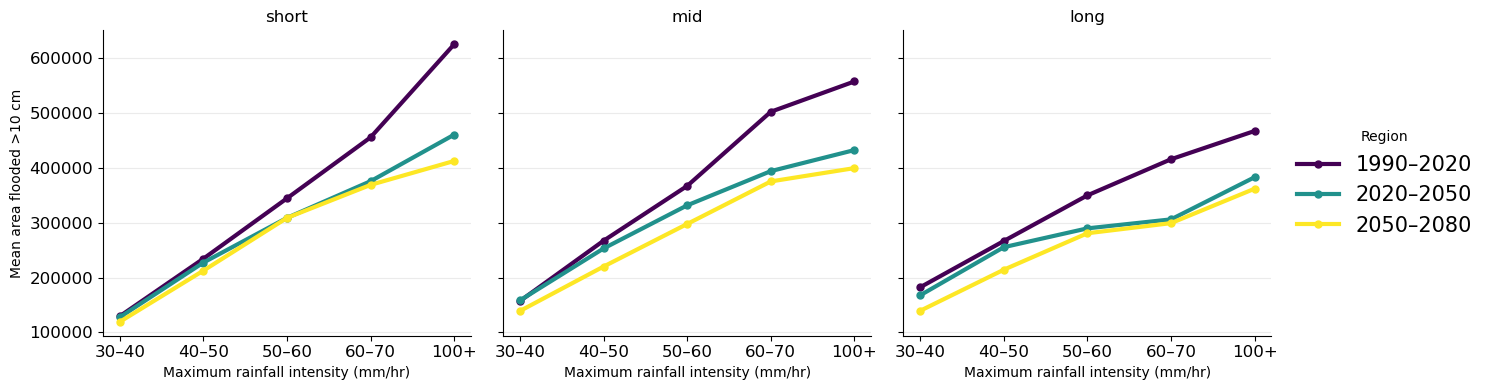

In [13]:
fig, ax = plt.subplots(ncols= 3, figsize=(15, 4), sharex=True, sharey=True)
ax_num=0
lengths = {'short': (0, 10),'mid': (10, 30), 'long':  (30, 200),}
colors = plt.cm.viridis(np.linspace(0, 1, len(periods)))

for label, (y0, y1) in lengths.items():
    mask = (rainfall_events_all_df['length_of_active_rain'] >= y0) & (rainfall_events_all_df['length_of_active_rain'] <= y1)
    df = rainfall_events_all_df.loc[mask]
    summary = (df.groupby(["period", "intensity_bin"], observed=True)["10cm_volume"].mean().unstack())
    
    # Your plot currently reverses the region order, so make the same mapping
    region_colors = dict(zip(periods, colors))

    for region, color in zip(periods, colors):
        ax[ax_num].plot(summary.columns,summary.loc[region],marker="o",linewidth=3,markersize=5,color=color,label=region)

    ax[ax_num].set_xlabel("Maximum rainfall intensity (mm/hr)")
    if ax_num == 0:
        ax[ax_num].set_ylabel("Mean area flooded >10 cm")
    #ax[ax_num].set_title("Mean per-event flooded area across intensity bins",
    #             fontsize=20, pad=12)
    
    ax[ax_num].set_title(label)
    ax[ax_num].grid(axis="y", alpha=0.25)
    ax[ax_num].spines["top"].set_visible(False)
    ax[ax_num].spines["right"].set_visible(False)
    ax[ax_num].tick_params(axis="both", which="major", labelsize=12)
    
    if ax_num == 2:
        ax[ax_num].legend(title="Region",bbox_to_anchor=(1.02, 0.5),loc="center left",frameon=False,fontsize=15)
    
    ax_num =ax_num+1
    
fig.tight_layout()

In [14]:
# event_counts = (
#     rainfall_events_all_df
#     .groupby(["period", "intensity_bin"], observed=True)
#     .size()
#     .unstack())
# print(event_counts)

# # And specifically: which regions have ANY events in the 100+ bin, by period?
# contributing_regions = (
#     rainfall_events_all_df[rainfall_events_all_df["intensity_bin"] == "100+"]
#     .groupby(["period", "geo_region"], observed=True)
#     .size()
#     .unstack(fill_value=0))
# contributing_regions

In [15]:
# for region in reversed(region_order):
#     this_region = rainfall_events_all_df[rainfall_events_all_df['geo_region']==region]
    
#     fig, ax = plt.subplots(ncols= 3, figsize=(15, 4), sharex=True, sharey=True)
#     ax_num=0
#     lengths = {'short': (0, 10),'mid': (10, 30), 'long':  (30, 200),}
#     colors = plt.cm.viridis(np.linspace(0, 1, len(periods)))

#     for label, (y0, y1) in lengths.items():
#         mask = (this_region['length_of_active_rain'] >= y0) & (this_region['length_of_active_rain'] <= y1)
#         df = this_region.loc[mask]
#         summary = (df.groupby(["period", "intensity_bin"], observed=True)["10cm_volume"].mean().unstack())

#         # Your plot currently reverses the region order, so make the same mapping
#         region_colors = dict(zip(periods, colors))

#         for choice, color in zip(periods, colors):
#             ax[ax_num].plot(summary.columns,summary.loc[choice],marker="o",linewidth=3,markersize=5,color=color,label=choice)

#         ax[ax_num].set_xlabel("Maximum rainfall intensity (mm/hr)")
#         if ax_num == 0:
#             ax[ax_num].set_ylabel("Mean area flooded >10 cm")
#         #ax[ax_num].set_title("Mean per-event flooded area across intensity bins",
#         #             fontsize=20, pad=12)

#         ax[ax_num].set_title(label)
#         ax[ax_num].grid(axis="y", alpha=0.25)
#         ax[ax_num].spines["top"].set_visible(False)
#         ax[ax_num].spines["right"].set_visible(False)
#         ax[ax_num].tick_params(axis="both", which="major", labelsize=12)

#         if ax_num == 2:
#             ax[ax_num].legend(title=region,bbox_to_anchor=(1.02, 0.5),loc="center left",frameon=False,fontsize=15)

#         ax_num =ax_num+1

#     fig.tight_layout()
#     fig.suptitle(region)

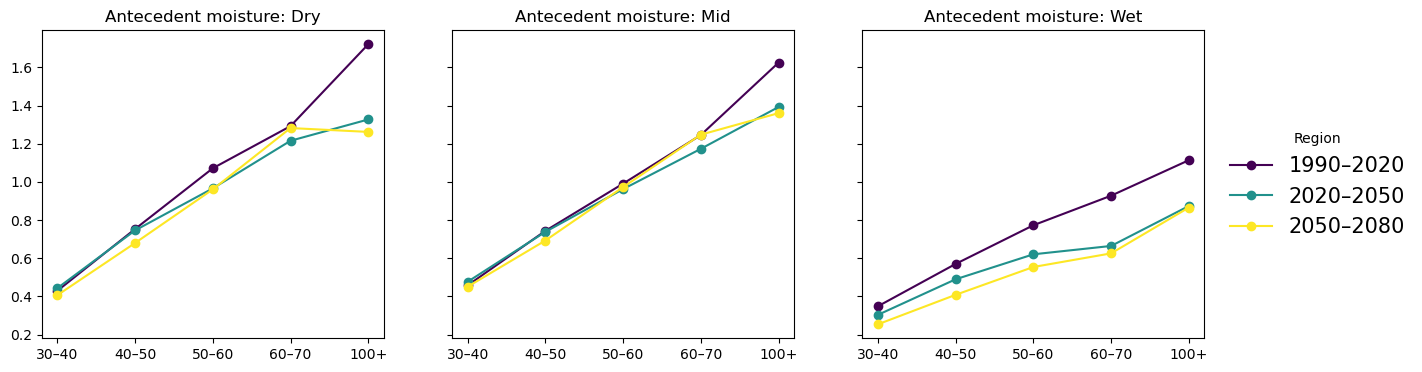

In [20]:
color_map = dict(zip(periods, colors))

rainfall_events_all_df["moisture_bin"] = pd.qcut(rainfall_events_all_df["mean_sm_2_before_event"], 3, labels=["Dry", "Mid", "Wet"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, m_bin in zip(axes, ["Dry", "Mid", "Wet"]):
    sub = rainfall_events_all_df[rainfall_events_all_df["moisture_bin"] == m_bin]
    summary = sub.groupby(["period", "intensity_bin"], observed=True)["10cm_area"].mean().unstack()
    for period in periods:
        if period in summary.index:
            ax.plot(summary.columns, summary.loc[period], marker="o", color=color_map[period], label=period)
    ax.set_title(f"Antecedent moisture: {m_bin}")
    if m_bin == 'Wet':
        ax.legend(title="Region",bbox_to_anchor=(1.02, 0.5),loc="center left",frameon=False,fontsize=15)

In [179]:
target_bin = '30–40'
season_mix = (rainfall_events_all_df
    .groupby(['period', 'season'], observed=True).size()
    .groupby(level=0).apply(lambda x: x / x.sum())
    .unstack())

,season,DJF,JJA,MAM,SON
period,period,,,,
1990–2020,1990–2020,0.012345,0.782753,0.043879,0.161023
2020–2050,2020–2050,0.046529,0.657871,0.066478,0.229122
2050–2080,2050–2080,0.081989,0.557881,0.072999,0.287130


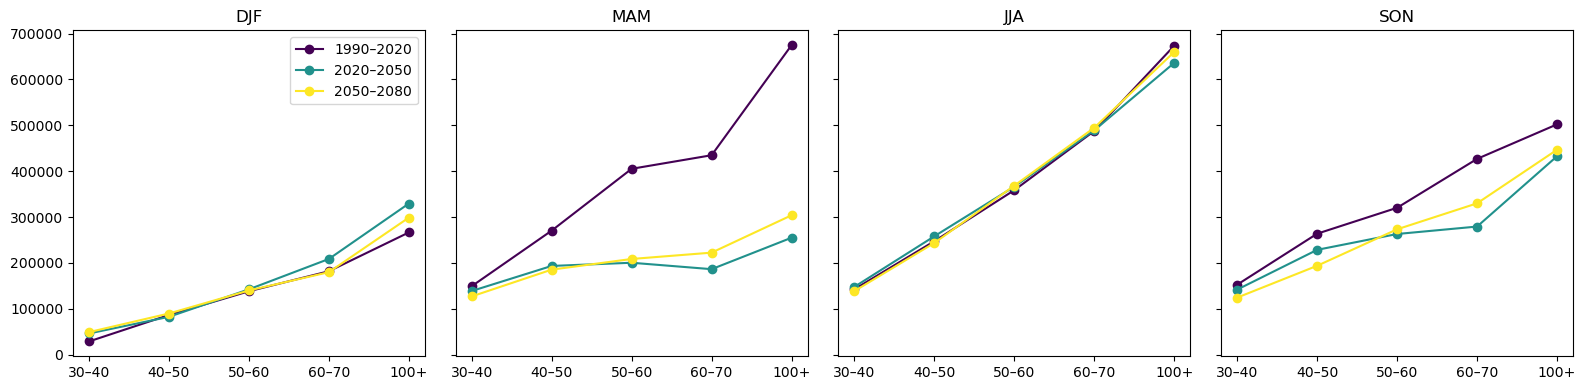

In [159]:
fig, axes = plt.subplots(1, 4, figsize=(16,4), sharey=True)
for ax, season in zip(axes, ['DJF','MAM','JJA','SON']):
    sub = rainfall_events_all_df[rainfall_events_all_df['season'] == season]
    summary = sub.groupby(["period", "intensity_bin"], observed=True)["10cm_volume"].mean().unstack()
    for choice in periods:
        if choice in summary.index:
            ax.plot(summary.columns, summary.loc[choice], marker="o", color=color_map[choice], label=choice)
    ax.set_title(season)
axes[0].legend()
plt.tight_layout()
plt.show()

In [167]:
from scipy import stats

trend_results = []
period_numeric = {'1990–2020': 0, '2020–2050': 1, '2050–2080': 2}  # adjust to your actual labels

for region in region_order:
    # Get data just this region
    sub = rainfall_events_all_df[rainfall_events_all_df['geo_region'] == region]
    # For each intensity bin
    for ibin in sub['intensity_bin'].cat.categories:
        bsub = sub[sub['intensity_bin'] == ibin].copy()
        bsub['period_num'] = bsub['period'].map(period_numeric)
        if bsub['period_num'].nunique() < 2:
            continue
        slope, intercept, r, p, se = stats.linregress(bsub['period_num'], bsub['10cm_volume'])
        trend_results.append({'region': region, 'intensity_bin': ibin, 'slope': slope, 'p_value': p, "se": se})

trend_df = pd.DataFrame(trend_results)
# trend_df[trend_df['p_value'] < 0.05]  # which region/bin combinations show a credible trend

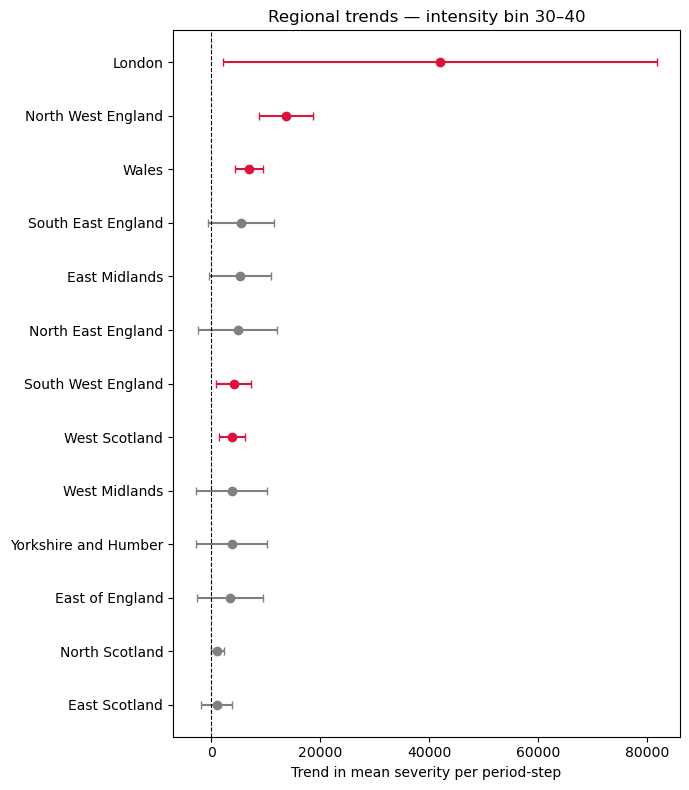

In [164]:
fig, ax = plt.subplots(figsize=(7, 8))

sub = trend_df[trend_df['intensity_bin'] == target_bin].sort_values('slope').reset_index(drop=True)
y_pos = np.arange(len(sub))

for i, row in sub.iterrows():
    color = 'crimson' if row['p_value'] < 0.05 else 'grey'
    ax.errorbar(row['slope'], y_pos[i], xerr=1.96*row['se'], fmt='o', capsize=3, color=color)

ax.axvline(0, color='k', lw=0.8, linestyle='--')
ax.set_yticks(y_pos)
ax.set_yticklabels(sub['region'])
ax.set_xlabel('Trend in mean severity per period-step')
ax.set_title(f'Regional trends — intensity bin {target_bin}')
plt.tight_layout()
plt.show()

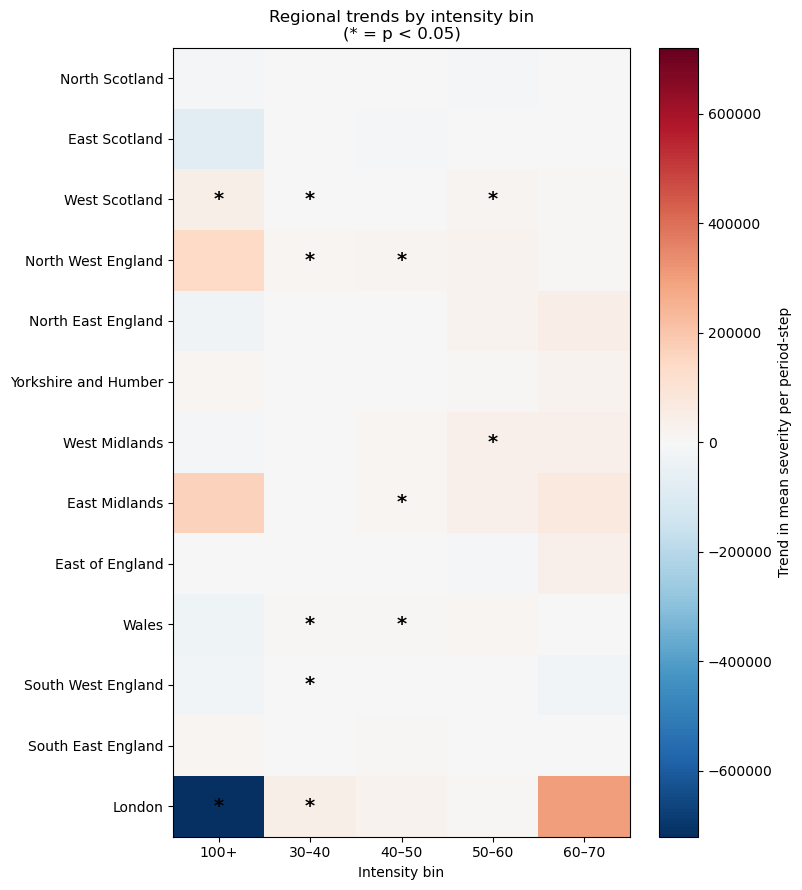

In [165]:
# Pivot trend_df into a region x intensity_bin grid of slopes
slope_grid = trend_df.pivot(index='region', columns='intensity_bin', values='slope')
pval_grid = trend_df.pivot(index='region', columns='intensity_bin', values='p_value')

# Order rows consistently (e.g. by overall mean slope, or your existing region_order)
slope_grid = slope_grid.reindex(region_order)
pval_grid = pval_grid.reindex(region_order)

fig, ax = plt.subplots(figsize=(8, 9))

vmax = np.nanmax(np.abs(slope_grid.values))
im = ax.imshow(slope_grid.values, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto')

# Mark significant cells with an asterisk
for i in range(slope_grid.shape[0]):
    for j in range(slope_grid.shape[1]):
        p = pval_grid.values[i, j]
        if not np.isnan(p) and p < 0.05:
            ax.text(j, i, '*', ha='center', va='center', color='black', fontsize=14, fontweight='bold')

ax.set_xticks(range(len(slope_grid.columns)))
ax.set_xticklabels(slope_grid.columns)
ax.set_yticks(range(len(slope_grid.index)))
ax.set_yticklabels(slope_grid.index)
ax.set_xlabel('Intensity bin')
plt.colorbar(im, ax=ax, label='Trend in mean severity per period-step')
ax.set_title('Regional trends by intensity bin\n(* = p < 0.05)')
plt.tight_layout()
plt.show()

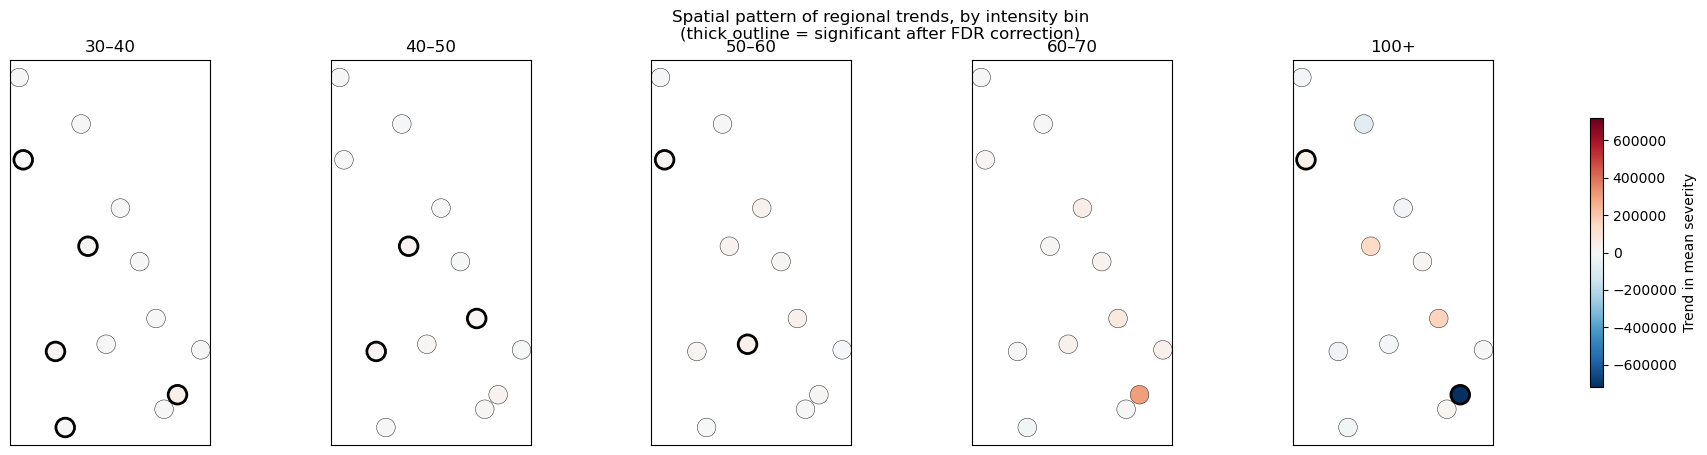

In [166]:
# Reconcile column naming between trend_df ('region') and the main dataframe ('geo_region')
region_centroids = (
    rainfall_events_all_df.groupby('geo_region')[['x_coord', 'y_coord']]
    .mean().reset_index().rename(columns={'geo_region': 'region'}))

trend_with_coords = trend_df.merge(region_centroids, on='region', how='left')

intensity_bins_available = trend_with_coords['intensity_bin'].cat.categories if hasattr(trend_with_coords['intensity_bin'], 'cat') else trend_with_coords['intensity_bin'].unique()

fig, axes = plt.subplots(1, len(intensity_bins_available), figsize=(5*len(intensity_bins_available), 5), sharex=True, sharey=True)

vmax = np.nanmax(np.abs(trend_with_coords['slope']))

for ax, ibin in zip(axes, intensity_bins_available):
    sub = trend_with_coords[trend_with_coords['intensity_bin'] == ibin]
    edgewidths = np.where(sub['p_value'] < 0.05, 2.0, 0.3)  # use p_adjusted if you've applied the FDR correction

    sc = ax.scatter(sub['x_coord'], sub['y_coord'], c=sub['slope'], cmap='RdBu_r',
                     vmin=-vmax, vmax=vmax, s=180, edgecolor='k', linewidth=edgewidths)
    ax.set_title(ibin)
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])

fig.colorbar(sc, ax=axes, label='Trend in mean severity', shrink=0.7)
fig.suptitle('Spatial pattern of regional trends, by intensity bin\n(thick outline = significant after FDR correction)')
plt.show()